# Cybertron - EN3150 Assignment 03


In [1]:
import os
if not os.path.exists('requirements.txt'):
    !git clone -q https://github.com/Isira-Himal-Perera/CNN-for-Edge-Image-Classification.git repo
    %cd repo
!pip install -q -r requirements.txt
print('working directory:', os.getcwd())

/content/repo
working directory: /content/repo


In [2]:
from pathlib import Path
import torch
from IPython.display import Image, display

from src.data import get_data, make_loaders, SEED
from src.models import EdgeCNN, count_params, estimate_macs, load_pretrained, unfreeze_last_block
from src.experiment import seed_everything, optimizer_for, run_epochs, evaluate, describe_run

%matplotlib inline
import matplotlib.pyplot as plt

OUT = Path('results_notebook')
(OUT / 'models').mkdir(parents=True, exist_ok=True)
(OUT / 'plots').mkdir(parents=True, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch:', torch.__version__)

device: cuda | torch: 2.11.0+cu130


### Dataset

Splits digits 70/15/15 with seed 42 and previews sixteen training samples.

train: 1257 images (69.9%)
val  :  270 images (15.0%)
test :  270 images (15.0%)
classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


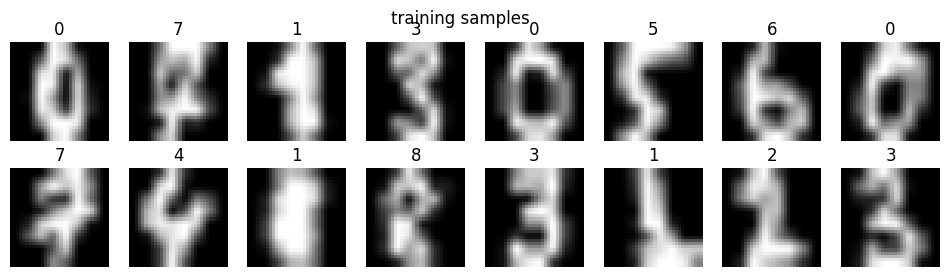

In [3]:
splits, classes, metadata = get_data('digits')
loaders = make_loaders(splits, batch_size=64)
image_size = splits['train'][0].shape[-1]

for name, (x, y) in splits.items():
    print(f'{name:5s}: {len(y):4d} images ({100 * len(y) / 1797:.1f}%)')
print('classes:', classes)

x, y = splits['train']
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for ax, img, label in zip(axes.flat, x[:16], y[:16]):
    ax.imshow(img[0], cmap='gray')
    ax.set_title(str(int(label)))
    ax.axis('off')
fig.suptitle('training samples')
plt.show()

### Models

Builds both CNNs and prints parameter counts and per-image MACs.

In [4]:
model_a = EdgeCNN(len(classes), lightweight=False)
model_b = EdgeCNN(len(classes), lightweight=True)

for name, m in [('Model A (standard)', model_a), ('Model B (separable)', model_b)]:
    params = count_params(m)
    print(f'{name:22s} params={params:>7,d}  MACs/image={estimate_macs(m, image_size):,}')

assert count_params(model_b) <= 100_000, 'Model B exceeds the 100k parameter limit'
print('Model B is within the 100k parameter limit')

Model A (standard)     params= 26,218  MACs/image=2,804,032
Model B (separable)    params=  5,813  MACs/image=396,608
Model B is within the 100k parameter limit


### Training helpers

Defines the train and evaluate helpers that every run below calls.

In [5]:
def train(model, epochs, optim_name, lr=None, history=None):
    seed_everything()
    opt = optimizer_for(optim_name, model, lr)
    return run_epochs(model, loaders, epochs, opt, device, history)


def evaluate_and_plot(stem, model, history):
    metrics = evaluate(model, loaders['test'], len(classes), device)
    rec = describe_run(model, history, metrics, OUT, stem, classes, image_size, device)
    display(Image(filename=str(OUT / 'plots' / f'{stem}_loss.png')))
    display(Image(filename=str(OUT / 'plots' / f'{stem}_confusion.png')))
    print(f"{stem}: test accuracy {100 * metrics['accuracy']:.1f}%  "
          f"macro precision {100 * metrics['precision_macro']:.1f}%  "
          f"macro recall {100 * metrics['recall_macro']:.1f}%\n")
    return rec


results = {}

### Model A with Adam

Trains Model A for 25 epochs and writes its loss curve, confusion matrix and test metrics.

RUNNING: model_a_adam
epoch 01 train-loss=2.1785 val-loss=2.2975 val-accuracy=0.104 time=3.8s
epoch 02 train-loss=1.9239 val-loss=2.1514 val-accuracy=0.159 time=0.1s
epoch 03 train-loss=1.6154 val-loss=1.7148 val-accuracy=0.519 time=0.1s
epoch 04 train-loss=1.2618 val-loss=1.2571 val-accuracy=0.859 time=0.2s
epoch 05 train-loss=0.9451 val-loss=0.9347 val-accuracy=0.848 time=0.3s
epoch 06 train-loss=0.6799 val-loss=0.7118 val-accuracy=0.863 time=0.2s
epoch 07 train-loss=0.4904 val-loss=0.4878 val-accuracy=0.937 time=0.2s
epoch 08 train-loss=0.3714 val-loss=0.7994 val-accuracy=0.726 time=0.2s
epoch 09 train-loss=0.2819 val-loss=0.4334 val-accuracy=0.896 time=0.2s
epoch 10 train-loss=0.2187 val-loss=0.2908 val-accuracy=0.952 time=0.2s
epoch 11 train-loss=0.1734 val-loss=0.2034 val-accuracy=0.981 time=0.1s
epoch 12 train-loss=0.1318 val-loss=0.2131 val-accuracy=0.978 time=0.2s
epoch 13 train-loss=0.1064 val-loss=0.3674 val-accuracy=0.885 time=0.1s
epoch 14 train-loss=0.0941 val-loss=0.2108

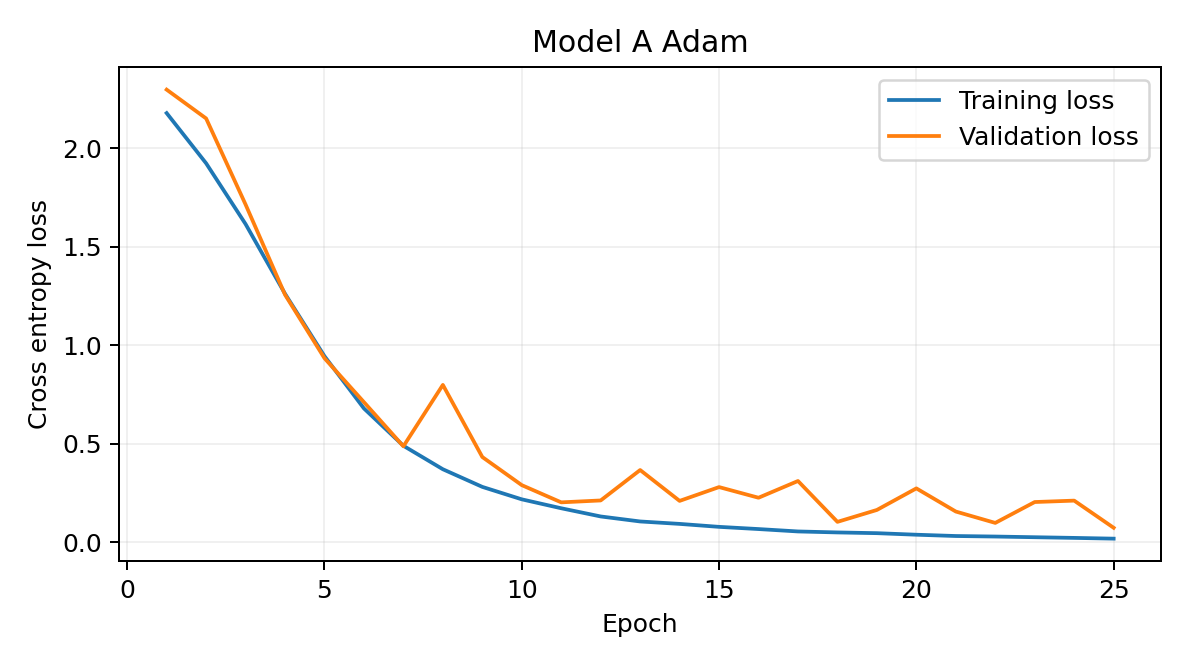

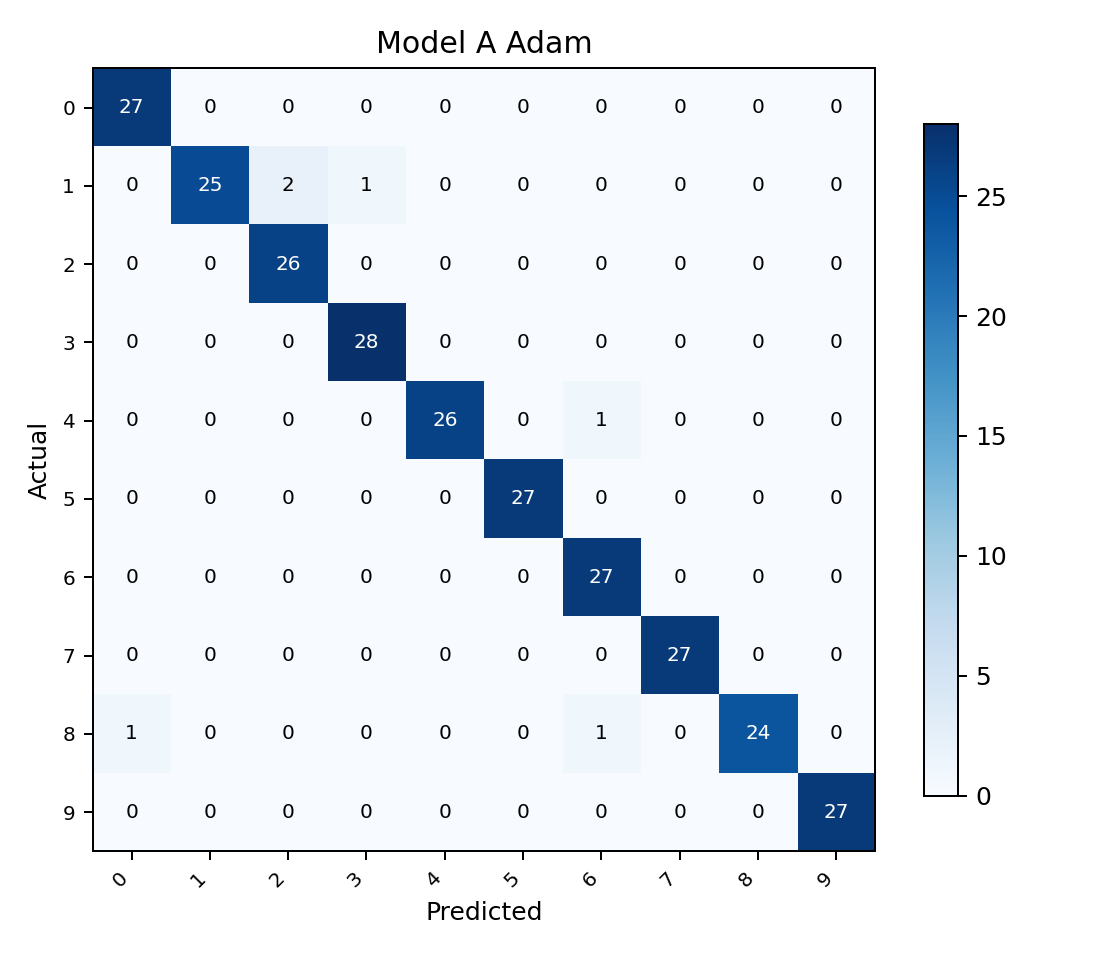

model_a_adam: test accuracy 97.8%  macro precision 97.9%  macro recall 97.8%



In [6]:
print('RUNNING: model_a_adam')
m = EdgeCNN(len(classes), lightweight=False)
hist = train(m, 25, 'adam')
results['model_a_adam'] = evaluate_and_plot('model_a_adam', m, hist)